<center><h1>Steven-Schneider_Isla_HW5</h1></center>
<br>
<br>

Name: Isla Steven-Schneider
<br>
Github Username: islastevenschneider
<br>
USC ID: 1985-4980-09

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from xgboost import XGBRegressor
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
np.random.seed(1030)

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
col_names = ['temp', 'nausea', 'lumbar', 'urine', 'micturition', 'urethra',
             'label_inflammation_urinary', 'label_nephritis']

df = pd.read_csv('diagnosis.data', sep='\t', header=None, names=col_names,
                 decimal=',', encoding='utf-16')

for col in col_names[1:]:
    df[col] = df[col].map({'yes': 1, 'no': 0})

### (b) Build a decision tree

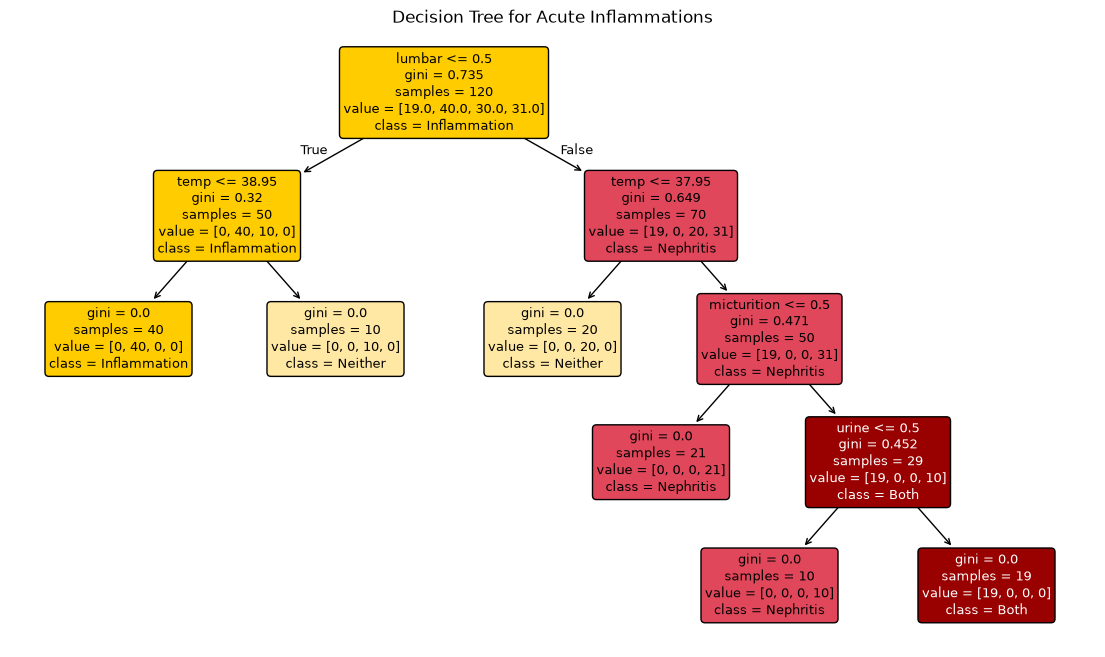

In [3]:
X = df.drop(columns=['label_inflammation_urinary', 'label_nephritis'])

# Combining the 2 labels into one 4-class label
combo = df['label_inflammation_urinary'].astype(str) + df['label_nephritis'].astype(str)
y = combo.map({'00': 'Neither', '10': 'Inflammation', '01': 'Nephritis', '11': 'Both'})

tree = DecisionTreeClassifier(criterion='gini', random_state=1030)
tree.fit(X, y)

# Class colors
colors = {'Neither': '#FFE8A3', 'Inflammation': '#FFCC00',
          'Nephritis': '#E0475B', 'Both': '#990000'}

plt.figure(figsize=(14, 8))
nodes = plot_tree(tree, feature_names=X.columns, class_names=tree.classes_,
                  filled=True, rounded=True)

# Changing color by majority class
boxes = [n for n in nodes if n.get_bbox_patch() is not None]
for i, node in enumerate(boxes):
    majority = tree.classes_[tree.tree_.value[i].argmax()]
    node.get_bbox_patch().set_facecolor(colors[majority])
    if majority == 'Both':
        node.set_color('white')

plt.title('Decision Tree for Acute Inflammations')
plt.show()

* Found label powerset to be the best fit since there are only 4 label combinations; this means the tree stays small enough to be interpretable and therefore useful enough to see how the diseases interact.

### (c) Convert the decision rules

In [4]:
def decision_rules(tree, feature_names):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] for i in tree.tree_.feature]
    value = tree.tree_.value

    def recurse(left, right, threshold, features, node, depth=0):
        indent = "    " * depth
        if (threshold[node] != -2):
            print(indent, "if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
            if left[node] != -1:
                recurse(left, right, threshold, features, left[node], depth+1)
                print(indent, "} else {")
                if right[node] != -1:
                    recurse(left, right, threshold, features, right[node], depth+1)
                print(indent, "}")
        else:
                print(indent, "return " + tree.classes_[value[node].argmax()])

    recurse(left, right, threshold, features, 0)

decision_rules(tree, list(X.columns))

 if ( lumbar <= 0.5 ) {
     if ( temp <= 38.95000076293945 ) {
         return Inflammation
     } else {
         return Neither
     }
 } else {
     if ( temp <= 37.95000076293945 ) {
         return Neither
     } else {
         if ( micturition <= 0.5 ) {
             return Nephritis
         } else {
             if ( urine <= 0.5 ) {
                 return Nephritis
             } else {
                 return Both
             }
         }
     }
 }


### (d) Cost-complexity pruning

In [5]:
alpha_values = tree.cost_complexity_pruning_path(X, y).ccp_alphas

cv_scores = []
for alpha in alpha_values:
    model = DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha, random_state=1030)
    folds = KFold(n_splits=5, shuffle=True, random_state=1030)
    cv_scores.append(cross_val_score(model, X, y, cv=folds).mean())

print('CV scores:', np.round(cv_scores, 3))

best_alpha = alpha_values[np.argmax(cv_scores)]
print('Best alpha:', best_alpha)

pruned_tree = DecisionTreeClassifier(criterion='gini', ccp_alpha=best_alpha, random_state=1030)
pruned_tree.fit(X, y)
print('Leaves:', pruned_tree.get_n_leaves())

decision_rules(pruned_tree, list(X.columns))

CV scores: [0.992 0.833 0.783 0.625 0.458]
Best alpha: 0.0
Leaves: 6
 if ( lumbar <= 0.5 ) {
     if ( temp <= 38.95000076293945 ) {
         return Inflammation
     } else {
         return Neither
     }
 } else {
     if ( temp <= 37.95000076293945 ) {
         return Neither
     } else {
         if ( micturition <= 0.5 ) {
             return Nephritis
         } else {
             if ( urine <= 0.5 ) {
                 return Nephritis
             } else {
                 return Both
             }
         }
     }
 }


The best tree is the one with all 6 leaves, i.e. no pruning (α = 0), with a cross-validation accuracy of 0.99. Adding a penalty only makes the error worse because, as seen above, just pruning one branch dropped the CV accuracy to 0.83. This means every split in the tree is needed to classify the patients correctly, so the full tree from above is already the minimal tree.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
col_names = []
for line in open('communities.names'):
    if line.startswith('@attribute'):
        col_names.append(line.split()[1])

crime_df = pd.read_csv('communities.data', header=None, names=col_names, na_values='?')

train_set = crime_df.iloc[:1495]
test_set = crime_df.iloc[1495:]

print(crime_df.shape, train_set.shape, test_set.shape)

(1994, 128) (1495, 128) (499, 128)


### (b) Missing values

In [7]:
drop_cols = ['state', 'county', 'community', 'communityname', 'fold']
train_set = train_set.drop(columns=drop_cols)
test_set = test_set.drop(columns=drop_cols)

test_set = test_set.fillna(train_set.median())
train_set = train_set.fillna(train_set.median())

print(train_set.shape, test_set.shape)
print(train_set.isna().sum().sum(), test_set.isna().sum().sum())

(1495, 123) (499, 123)
0 0


* I chose to fill missing values with median imputation calculated from the training set and applied to the training and test sets; deleting wasn’t feasible in this case since around 84% of the rows had missing police features.

### (c) Plot a correlation matrix

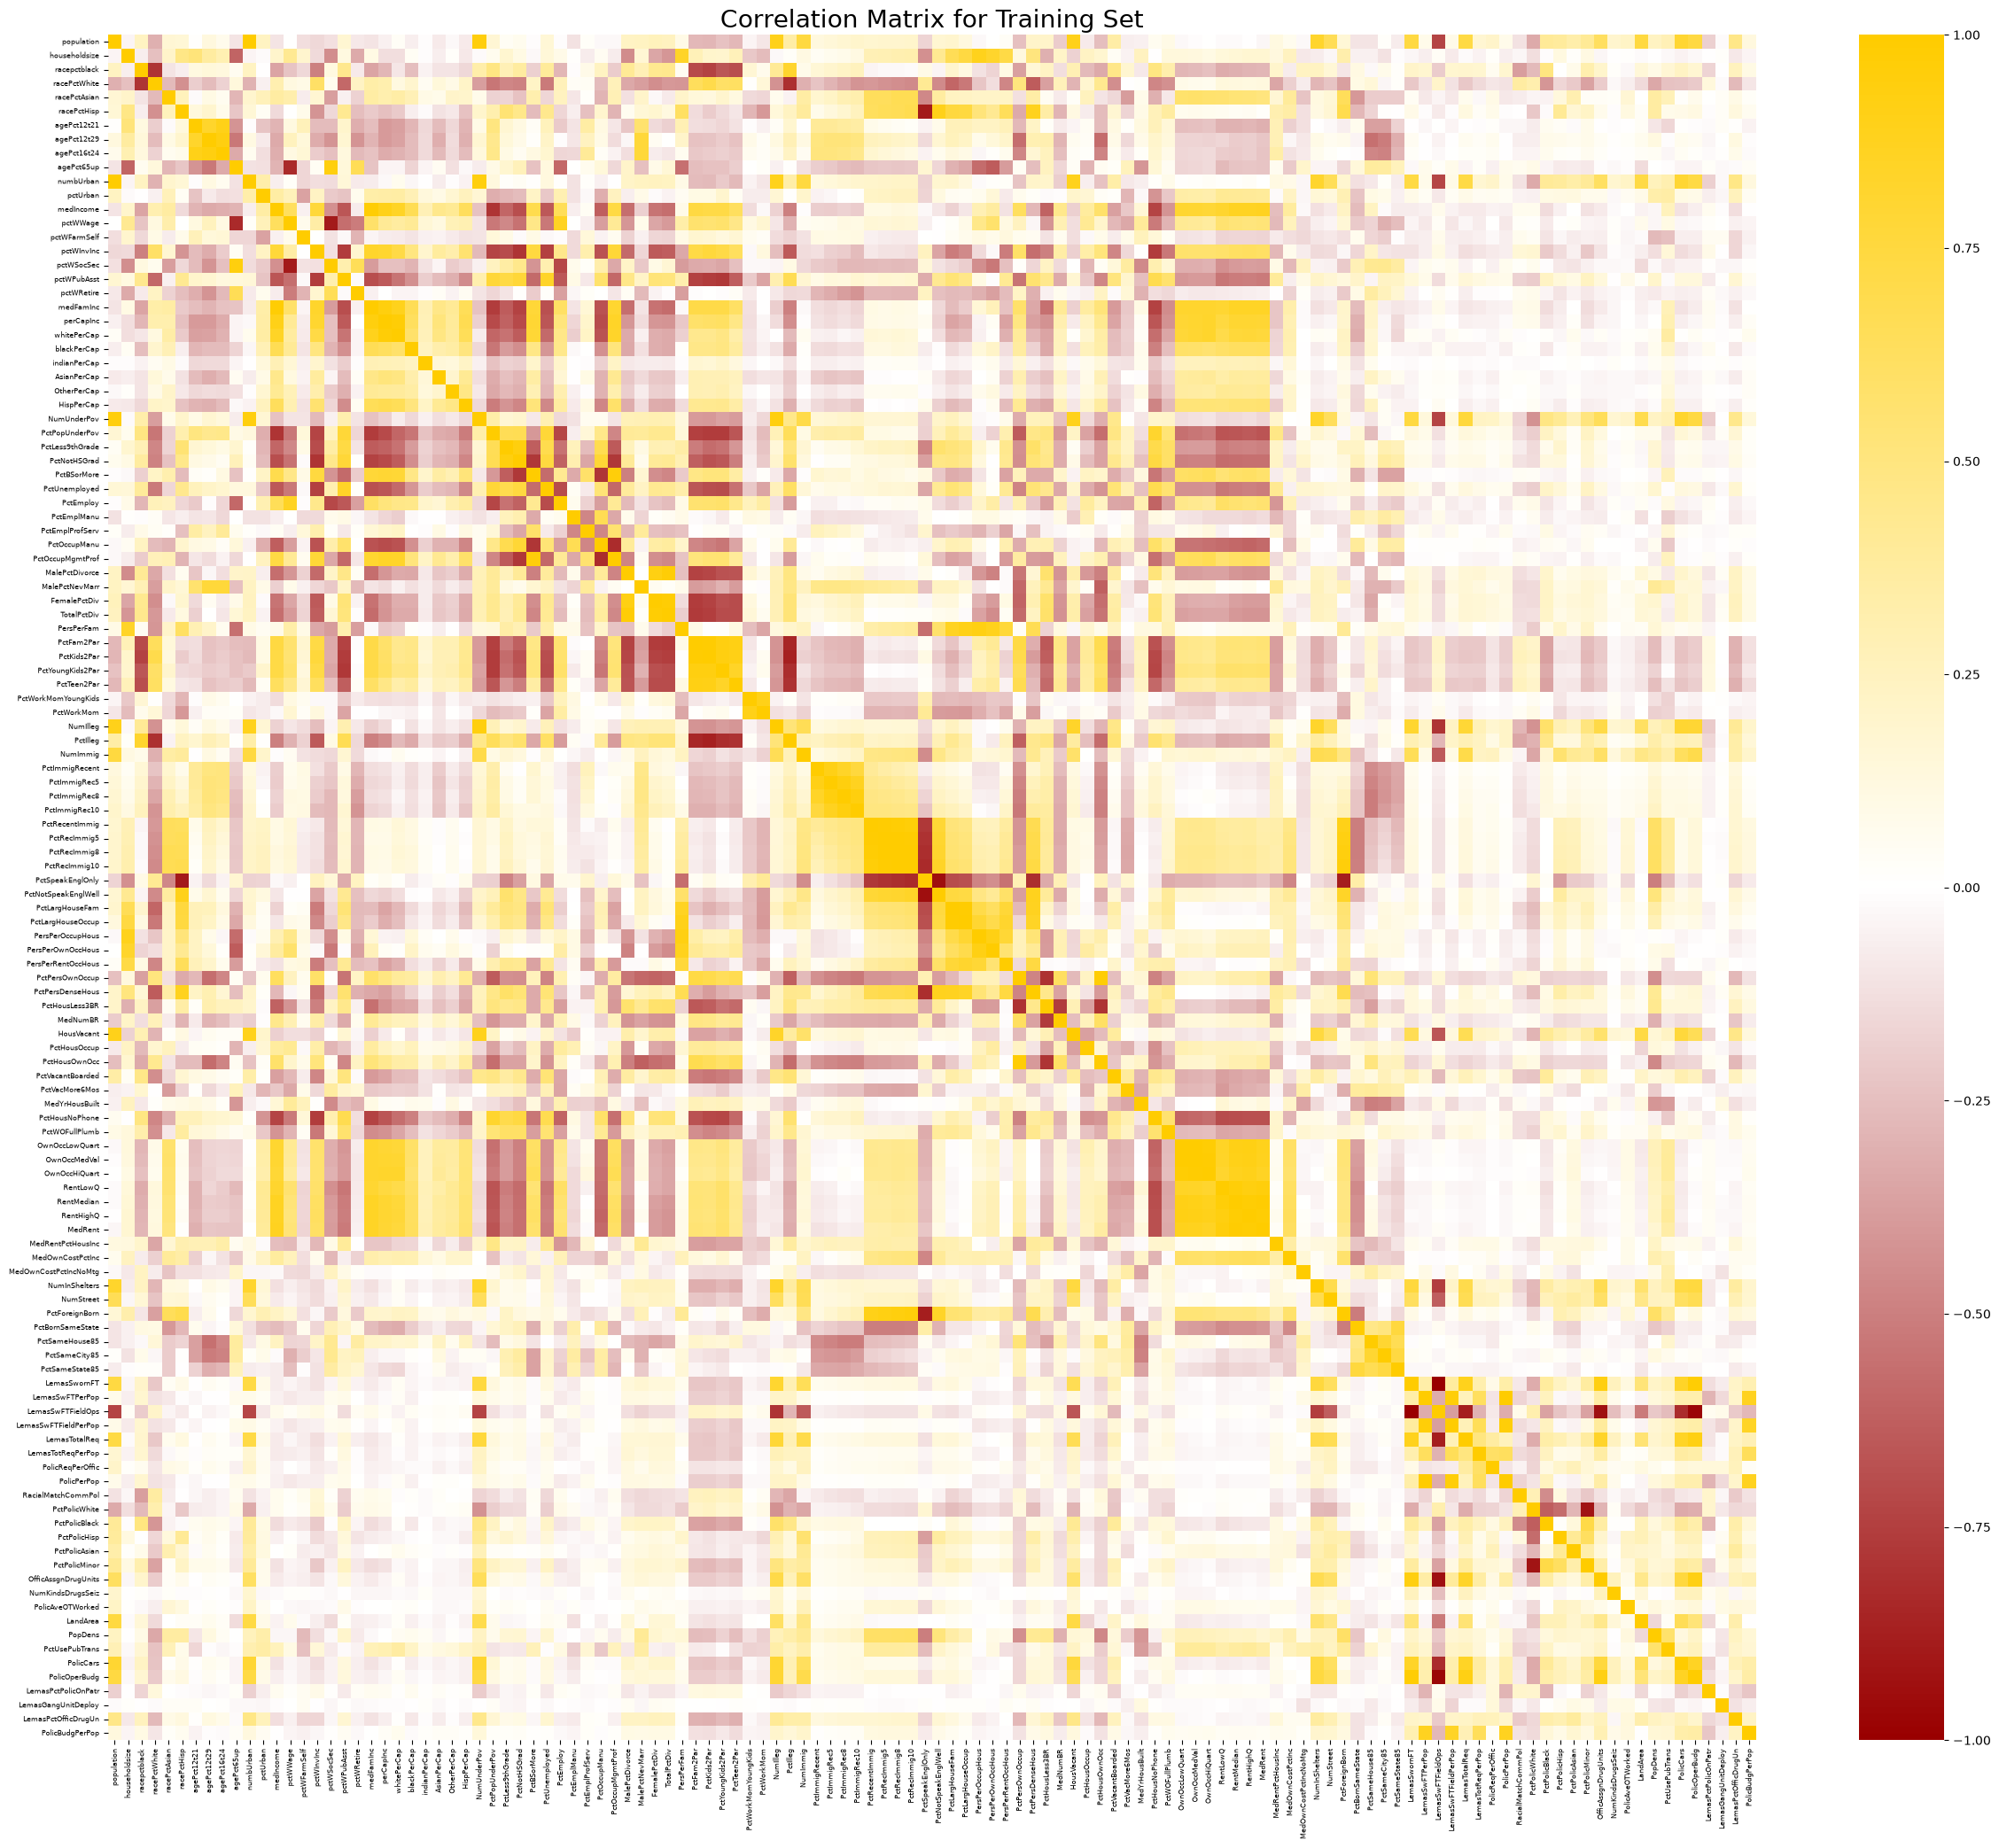

In [8]:
correlation = train_set.drop(columns=['ViolentCrimesPerPop']).corr()

red_gold = LinearSegmentedColormap.from_list('red_gold', ['#990000', 'white', '#FFCC00'])

plt.figure(figsize=(30, 25))
sns.heatmap(correlation, cmap=red_gold, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.title('Correlation Matrix for Training Set', fontsize=20)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
features = train_set.drop(columns=['ViolentCrimesPerPop'])

coef_var = (features.std() / features.mean()).sort_values(ascending=False)

print(coef_var.to_string())

PctPolicAsian            5.527059
NumStreet                4.292923
NumInShelters            3.470952
NumIlleg                 3.058964
NumImmig                 2.926635
LemasPctOfficDrugUn      2.552946
NumUnderPov              2.342443
LemasSwornFT             2.248042
population               2.241105
numbUrban                2.038461
HousVacant               1.968467
PolicOperBudg            1.645508
LandArea                 1.645408
racePctHisp              1.612091
PctNotSpeakEnglWell      1.456618
LemasTotalReq            1.451887
racepctblack             1.428885
PctUsePubTrans           1.397110
racePctAsian             1.359100
PctPolicHisp             1.353882
PctRecentImmig           1.288287
PctRecImmig5             1.286184
PctRecImmig10            1.270476
PctRecImmig8             1.265579
OfficAssgnDrugUnits      1.174565
PctPersDenseHous         1.132926
PolicCars                1.112831
PctForeignBorn           1.065880
PctVacantBoarded         1.054827
PctHousNoPhone

### (e) Scatter plots and box plots for highest CV features

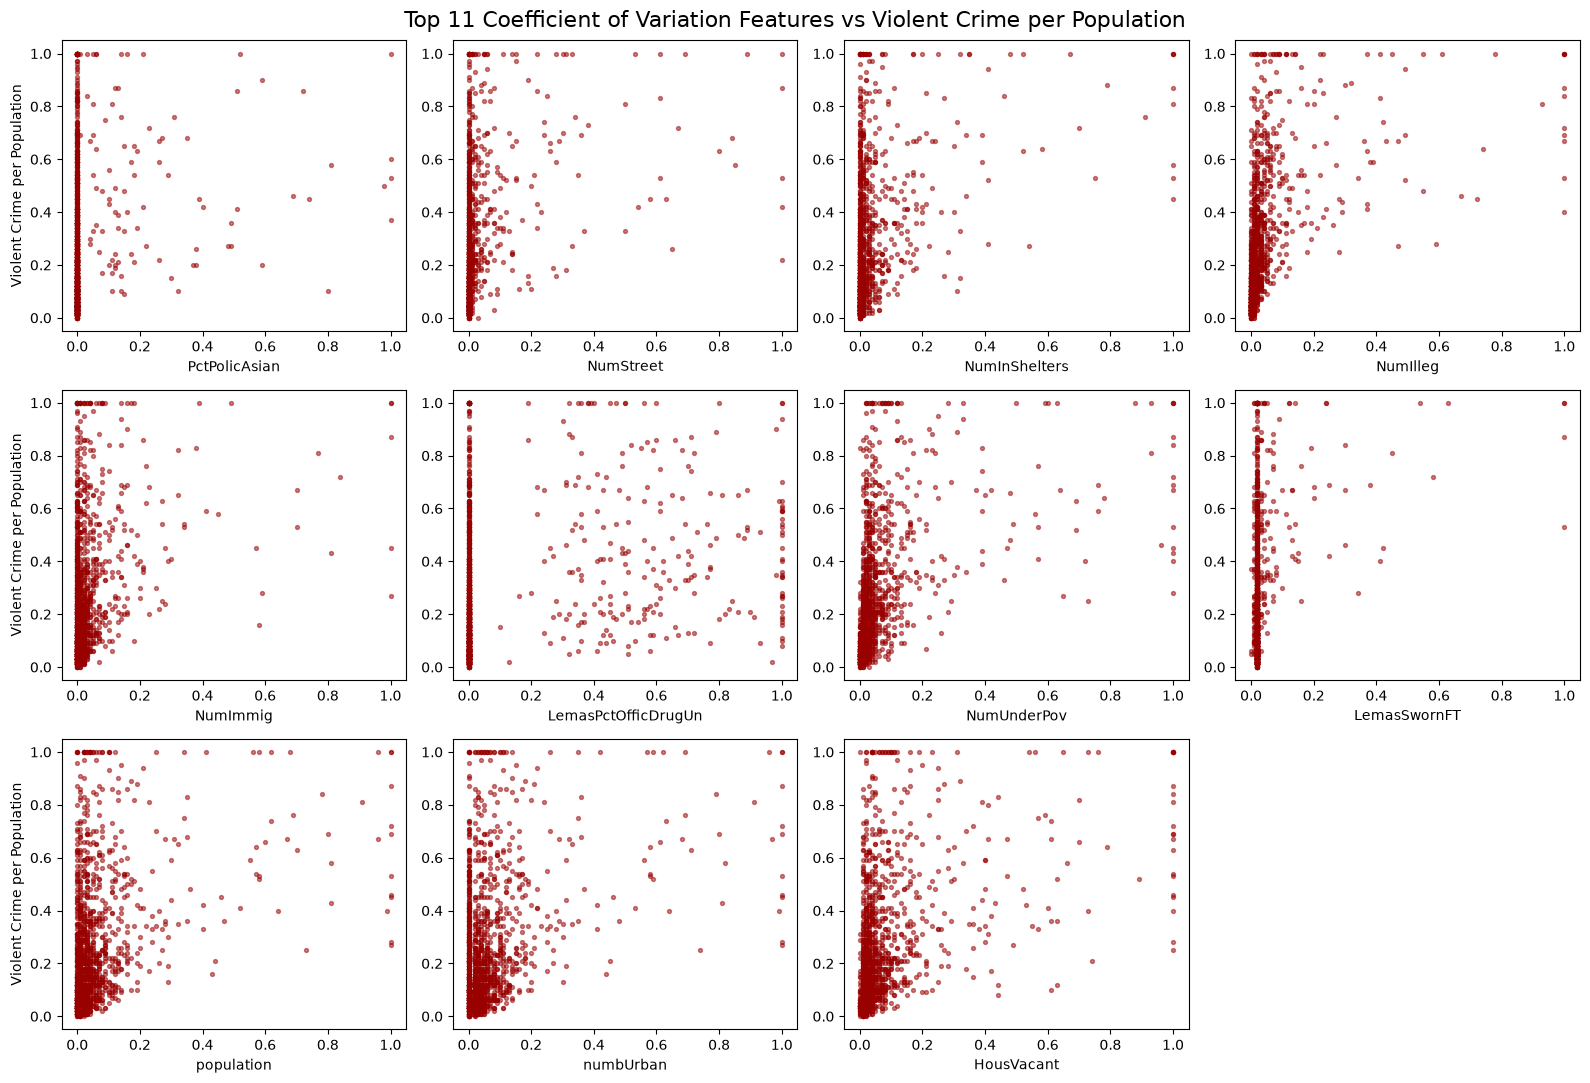

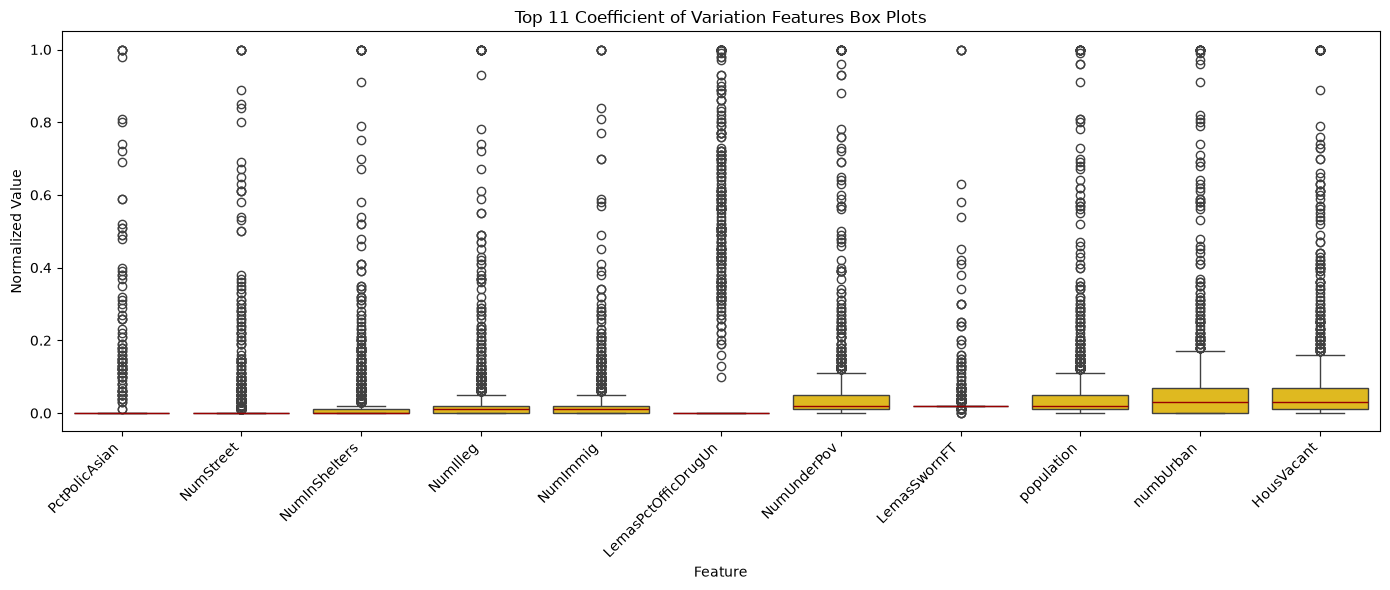

In [10]:
highest_coef_var = coef_var.index[:11]

# scatter plots: each feature vs the target
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for i, feature in enumerate(highest_coef_var):
    axes[i].scatter(train_set[feature], train_set['ViolentCrimesPerPop'],
                    color='#990000', s=8, alpha=0.5)
    axes[i].set_xlabel(feature)
    if i % 4 == 0:
        axes[i].set_ylabel('Violent Crime per Population')
axes[11].axis('off')
fig.suptitle('Top 11 Coefficient of Variation Features vs Violent Crime per Population', fontsize=16)
plt.tight_layout()
plt.show()

# box plots
plt.figure(figsize=(14, 6))
sns.boxplot(data=train_set[highest_coef_var], color='#FFCC00', medianprops={'color': '#990000'})
plt.xticks(rotation=45, ha='right')
plt.xlabel('Feature')
plt.ylabel('Normalized Value')
plt.title('Top 11 Coefficient of Variation Features Box Plots')
plt.tight_layout()
plt.show()

The scatter plots are helpful for understanding a trend visually, but you cannot use them to draw conclusions about the significance of the features. This is due to the fact that most of the features congregate around 0 with some outliers, so you cannot tell what is significant. Population could be interpreted as having a weak upward trend, but a statistical test would have to be done to actually determine significance, e.g. from the p-values.

### (f) Fit a linear model

In [11]:
train_X = train_set.drop(columns=['ViolentCrimesPerPop'])
train_y = train_set['ViolentCrimesPerPop']
test_X = test_set.drop(columns=['ViolentCrimesPerPop'])
test_y = test_set['ViolentCrimesPerPop']

linear_model = LinearRegression()
linear_model.fit(train_X, train_y)

linear_mse = mean_squared_error(test_y, linear_model.predict(test_X))
print('Least squares test MSE:', linear_mse)

Least squares test MSE: 0.017966215426067335


### (g) Fit a ridge regression model

In [12]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1030)
lambda_grid = np.logspace(-4, 4, 100)

ridge_cv_mse = []
for lam in lambda_grid:
    scores = cross_val_score(Ridge(alpha=lam), train_X, train_y, cv=kfold,
                             scoring='neg_mean_squared_error')
    ridge_cv_mse.append(-scores.mean())

best_lambda = lambda_grid[np.argmin(ridge_cv_mse)]
print('Best lambda:', best_lambda)

ridge_model = Ridge(alpha=best_lambda)
ridge_model.fit(train_X, train_y)

ridge_mse = mean_squared_error(test_y, ridge_model.predict(test_X))
print('Ridge test MSE:', ridge_mse)

Best lambda: 8.497534359086455
Ridge test MSE: 0.01739010538244876


### (h) Fit a LASSO model

In [13]:
lambda_grid = np.logspace(-6, 0, 100)

# LASSO for already normalized features
lasso_cv_mse = []
for lam in lambda_grid:
    scores = cross_val_score(Lasso(alpha=lam, max_iter=10000), train_X, train_y,
                             cv=kfold, scoring='neg_mean_squared_error')
    lasso_cv_mse.append(-scores.mean())

best_lambda = lambda_grid[np.argmin(lasso_cv_mse)]
lasso_model = Lasso(alpha=best_lambda, max_iter=10000)
lasso_model.fit(train_X, train_y)

lasso_mse = mean_squared_error(test_y, lasso_model.predict(test_X))
lasso_features = list(train_X.columns[lasso_model.coef_ != 0])

print('Best lambda:', best_lambda)
print('LASSO test MSE:', lasso_mse)
print('Number of variables selected:', len(lasso_features))
print(lasso_features)

# LASSO for standardized features
scaler = StandardScaler()
train_X_std = scaler.fit_transform(train_X)
test_X_std = scaler.transform(test_X)

lasso_std_cv_mse = []
for lam in lambda_grid:
    scores = cross_val_score(Lasso(alpha=lam, max_iter=10000), train_X_std, train_y,
                             cv=kfold, scoring='neg_mean_squared_error')
    lasso_std_cv_mse.append(-scores.mean())

best_lambda_std = lambda_grid[np.argmin(lasso_std_cv_mse)]
lasso_std_model = Lasso(alpha=best_lambda_std, max_iter=10000)
lasso_std_model.fit(train_X_std, train_y)

lasso_std_mse = mean_squared_error(test_y, lasso_std_model.predict(test_X_std))
lasso_std_features = list(train_X.columns[lasso_std_model.coef_ != 0])

print('Best lambda (standardized):', best_lambda_std)
print('LASSO test MSE (standardized):', lasso_std_mse)
print('Number of variables selected:', len(lasso_std_features))
print(lasso_std_features)

Best lambda: 0.0005336699231206312
LASSO test MSE: 0.017550161059416598
Number of variables selected: 32
['racepctblack', 'agePct12t29', 'pctUrban', 'pctWInvInc', 'pctWPubAsst', 'pctWRetire', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'PctPopUnderPov', 'MalePctDivorce', 'PctKids2Par', 'PctYoungKids2Par', 'PctWorkMom', 'PctIlleg', 'PctRecImmig10', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'PctWOFullPlumb', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctIncNoMtg', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'PolicReqPerOffic', 'LemasGangUnitDeploy', 'LemasPctOfficDrugUn']
Best lambda (standardized): 0.0032745491628777285
LASSO test MSE (standardized): 0.017444341163412647
Number of variables selected: 33
['racepctblack', 'racePctWhite', 'agePct12t29', 'pctUrban', 'pctWInvInc', 'pctWPubAsst', 'pctWRetire', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'MalePctDivorce', 'PctKids2Par', 'PctYoungKids2Par', 'PctWorkMom', 'P

The results between models are very similar. This points to the fact that the raw features are already normalized on a scale of 0-1, hence the values 0.01755 raw vs. 0.01744 standardized, meaning standardizing it dropped the test error only marginally. Both models also selected a similar set of variables (32 raw vs. 33 standardized), with 27 of them picked by both.

### (i) Fit a PCR model

In [14]:
pca_model = PCA()
train_X_pca = pca_model.fit_transform(train_X)
test_X_pca = pca_model.transform(test_X)

pcr_cv_mse = []
for m in range(1, 123):
    scores = cross_val_score(LinearRegression(), train_X_pca[:, :m], train_y,
                             cv=kfold, scoring='neg_mean_squared_error')
    pcr_cv_mse.append(-scores.mean())

m_star = np.argmin(pcr_cv_mse) + 1
print('Best M:', m_star)

pcr_model = LinearRegression()
pcr_model.fit(train_X_pca[:, :m_star], train_y)

pcr_mse = mean_squared_error(test_y, pcr_model.predict(test_X_pca[:, :m_star]))
print('PCR test MSE:', pcr_mse)

Best M: 13
PCR test MSE: 0.017758678929391696


### (j) Fit a boosting tree

In [15]:
alpha_grid = np.logspace(-4, 2, 30)

xgb_cv_mse = []
for a in alpha_grid:
    scores = cross_val_score(XGBRegressor(reg_alpha=a, random_state=1030), train_X, train_y,
                             cv=kfold, scoring='neg_mean_squared_error')
    xgb_cv_mse.append(-scores.mean())

alpha_star = alpha_grid[np.argmin(xgb_cv_mse)]
print('Best alpha:', alpha_star)

xgb_model = XGBRegressor(reg_alpha=alpha_star, random_state=1030)
xgb_model.fit(train_X, train_y)

xgb_mse = mean_squared_error(test_y, xgb_model.predict(test_X))
print('XGBoost test MSE:', xgb_mse)

Best alpha: 3.562247890262444
XGBoost test MSE: 0.017880701979400244
